## Create a Granta MI Session

Import the GRANTA_MIScriptingToolkit package, and create a connection to a Granta MI server.

In [1]:
import datetime
import GRANTA_MIScriptingToolkit as gdl
from GRANTA_MIScriptingToolkit import granta as mpy

usernameVal = 'STK_user'
passwordVal = 'P455w07d!'

session = mpy.connect('https://nanomecommons.grantami.com/mi_servicelayer', user_name=usernameVal, password=passwordVal)

## Get tabular data attribute information

In [2]:
dbKey = "MI_Blank_v2021"
tableName = "Indentation test data"
recordName = "SiNx CSM High-Speed"

db = session.get_db(db_key=dbKey)
table = db.get_table(tableName)
Indrecord = table.search_for_records_by_name(recordName)[0]
samplesVal = Indrecord.attributes["Mechanical properties matrix"].value[:]
samplesUnit = Indrecord.attributes["Mechanical properties matrix"]
samplesVal

[[[1381.766878], [49318.096], None, [225.479789049], [22.918054406], None, ''],
 [[1380.766449],
  [49318.094591],
  None,
  [226.28774654600002],
  [23.382299276],
  None,
  ''],
 [[1379.766409],
  [49318.09459],
  None,
  [229.07575873500002],
  [22.583721177],
  None,
  ''],
 [[1379.76643],
  [49319.094358],
  None,
  [225.733737082],
  [22.622964047000004],
  None,
  ''],
 [[1380.766554],
  [49319.094142],
  None,
  [222.225604451],
  [22.714910689],
  None,
  ''],
 [[1381.766454],
  [49319.094079],
  None,
  [228.388093269],
  [23.700846644000002],
  None,
  ''],
 [[1381.766377],
  [49320.09441],
  None,
  [213.41438126],
  [19.412981852],
  None,
  ''],
 [[1380.76641],
  [49320.094374],
  None,
  [231.491390457],
  [23.321198167],
  None,
  ''],
 [[1379.766122],
  [49320.094142],
  None,
  [225.494857991],
  [23.717600886],
  None,
  ''],
 [[1367.01996],
  [49319.601918],
  None,
  [215.46869141800002],
  [22.199563666],
  None,
  ''],
 [[1366.019587],
  [49319.601413],
  None,
 

# 1st option to load and to plot tabular data

In [3]:
columns=['X position (µm)', 'Y position (µm)', 'Z position (µm)', 'Elastic modulus (GPa)', 'Hardness (GPa)', 'Creep (nm)']

import pandas as pd
df = pd.DataFrame(samplesVal)
df = df.iloc[:, :-1]
for i in range(0, len(df.columns)):
    df[i] = df[i].str[0]
    df = df.rename(columns={i: columns[i]})
display(df)

,X position (µm),Y position (µm),Z position (µm),Elastic modulus (GPa),Hardness (GPa),Creep (nm)
0,1381.766878,49318.096000,None,225.479789,22.918054,None
1,1380.766449,49318.094591,None,226.287747,23.382299,None
2,1379.766409,49318.094590,None,229.075759,22.583721,None
3,1379.766430,49319.094358,None,225.733737,22.622964,None
4,1380.766554,49319.094142,None,222.225604,22.714911,None
...,...,...,...,...,...,...
112,1346.985124,49373.242808,None,237.651673,25.369999,None
113,1347.985568,49373.242903,None,231.249457,23.801860,None
114,1347.985568,49374.242212,None,223.647791,23.490188,None
115,1346.985001,49374.242277,None,233.693315,24.006257,None


<Axes: xlabel='Hardness (GPa)', ylabel='Elastic modulus (GPa)'>

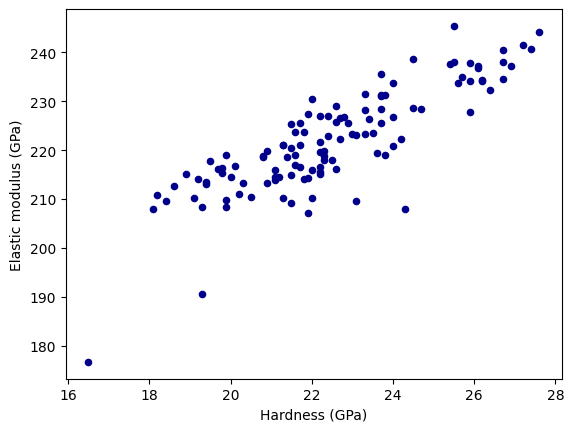

In [4]:
import matplotlib.pyplot as plt
df=df.round(1)
df.plot.scatter(x='Hardness (GPa)', y='Elastic modulus (GPa)', c='DarkBlue')

# 2nd option to load and to plot tabular data

<Axes: xlabel='Hardness (GPa)', ylabel='Elastic modulus (GPa)'>

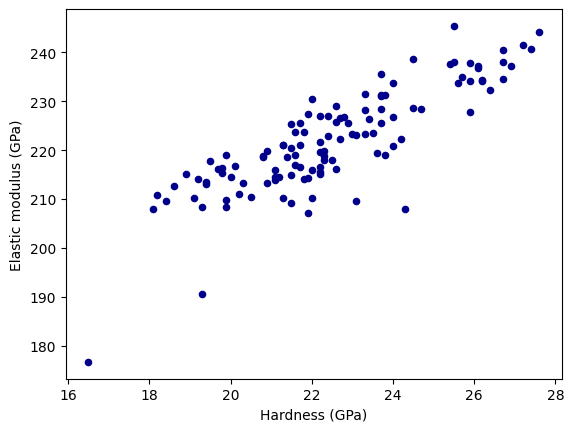

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

cleanData = []
for row in samplesVal:
    cleanRow = []
    for x in row:
        try:
            cleanRow.append(x[0])
        except:
            cleanRow.append(0)
    cleanData.append(cleanRow)
    

dfMat = pd.DataFrame(cleanData)
del dfMat[dfMat. columns[-1]]
dfMat.rename(columns = {0:'X coordinate (µm)', 
                        1:'Y coordinate (µm)', 
                        2:'Z coordinate (nm)', 
                        3:'Elastic modulus (GPa)', 
                        4:'Hardness (GPa)', 
                        5:'Creep (nm)'}, inplace = True)

dfMat=dfMat.round(1)
dfMat.plot.scatter(x='Hardness (GPa)', y='Elastic modulus (GPa)', c='DarkBlue')

## Plot heat map

     Elastic modulus (GPa)  Hardness (GPa)
0                    225.5            22.9
1                    226.3            23.4
2                    229.1            22.6
3                    225.7            22.6
4                    222.2            22.7
..                     ...             ...
112                  237.7            25.4
113                  231.2            23.8
114                  223.6            23.5
115                  233.7            24.0
116                  235.0            25.7

[117 rows x 2 columns]


<Axes: xlabel='Y coordinate (µm)', ylabel='X coordinate (µm)'>

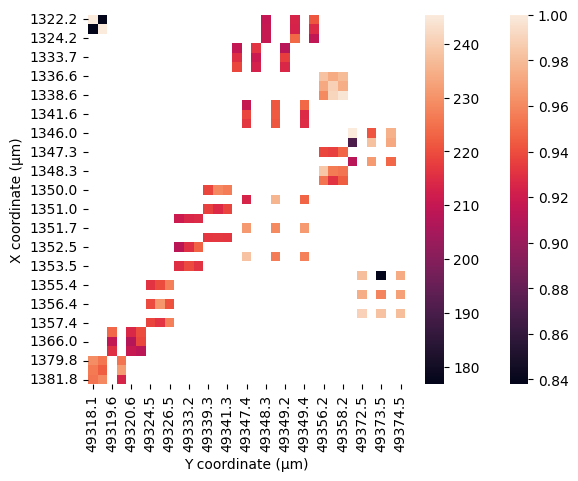

In [6]:
import seaborn as sns
%matplotlib inline

dfMat_E = dfMat[['Elastic modulus (GPa)', 'Hardness (GPa)']] #'X coordinate (µm)', 'Y coordinate (µm)', 
print(dfMat_E)

corr = dfMat_E.select_dtypes('number').corr()

# plot the heatmap
sns.heatmap(corr)

# plot the correlation heatmap
dFMatPivot = dfMat.pivot(index="X coordinate (µm)", columns="Y coordinate (µm)", values="Elastic modulus (GPa)")
sns.heatmap(dFMatPivot)

## Histogram plots and Gaussian deconvolution

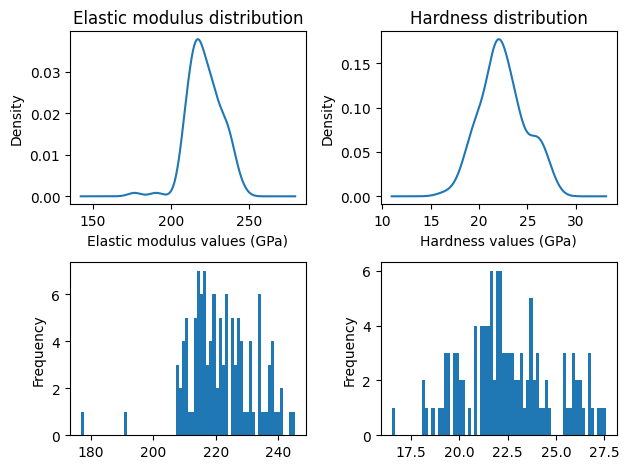

In [7]:
fig = plt.figure()
binsVal=round(df.size/10)

ax1 = fig.add_subplot(221)
ax1 = df['Elastic modulus (GPa)'].plot.kde()
ax11 = fig.add_subplot(223)
ax11 = df['Elastic modulus (GPa)'].plot.hist(bins=binsVal)
ax2 = fig.add_subplot(222)
ax2 = df['Hardness (GPa)'].plot.kde()
ax22 = fig.add_subplot(224)
ax22 = df['Hardness (GPa)'].plot.hist(bins=binsVal)
ax1.title.set_text('Elastic modulus distribution')
ax1.set_xlabel('Elastic modulus values (GPa)')
ax2.title.set_text('Hardness distribution')
ax2.set_xlabel('Hardness values (GPa)')
plt.tight_layout()
plt.show()

In [8]:
# Extract data from the KDE plot for Elastic modulus
kde_data_em = ax1.get_lines()[0].get_data()
x_values_em = kde_data_em[0]
y_values_em = kde_data_em[1]

# Extract data from the KDE plot for Hardness
kde_data_hardness = ax2.get_lines()[0].get_data()
x_values_hardness = kde_data_hardness[0]
y_values_hardness = kde_data_hardness[1]

# Now you can use x_values_em, y_values_em, x_values_hardness, and y_values_hardness as needed

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_23500\2622225974.py:14: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


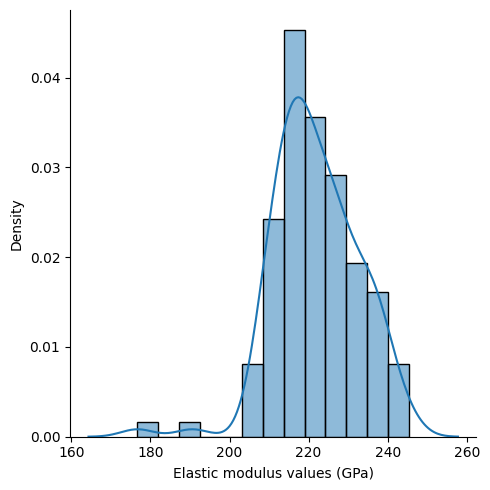

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_23500\2622225974.py:24: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


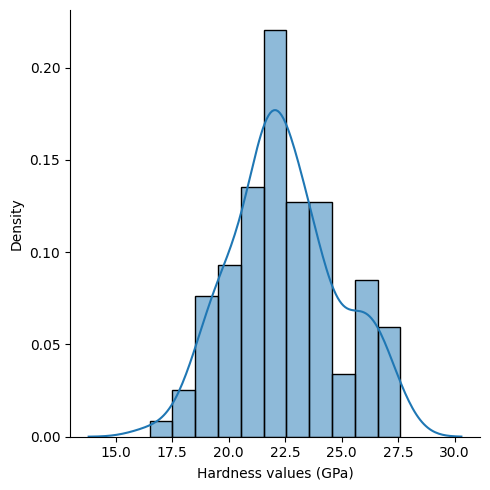

In [9]:
import seaborn as sns
from scipy.stats import norm

data = norm.rvs(5,0.4,size=1000) # you can use a pandas series or a list if you want

# Define subplots
ax1 = fig.add_subplot(221)
ax1 = sns.displot(df['Elastic modulus (GPa)'], kde=True,
    stat="density", kde_kws=dict(cut=3))
ax1.set_titles('Elastic modulus distribution')
ax1.set_xlabels('Elastic modulus values (GPa)')
plt.savefig('PDF_E.png', bbox_inches='tight')
plt.savefig('PDF_E.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()

ax2 = fig.add_subplot(222)
ax2 = sns.displot(df['Hardness (GPa)'], kde=True,
    stat="density", kde_kws=dict(cut=3))
ax2.set_titles('Hardness distribution')
ax2.set_xlabels('Hardness values (GPa)')
plt.savefig('PDF_H.png', bbox_inches='tight')
plt.savefig('PDF_H.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()


## K-means clustering analysis

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


[[214.48030303  21.04545455]
 [231.4372549   24.3372549 ]]


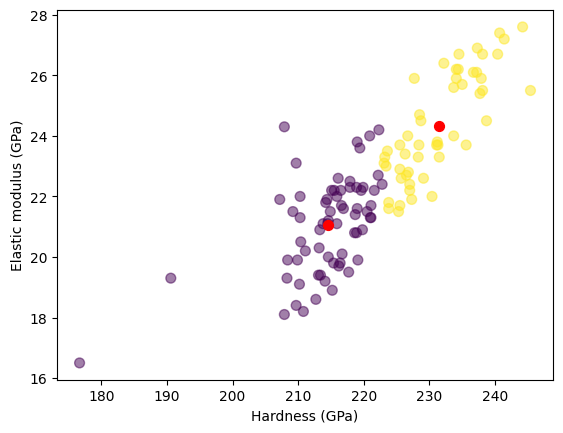

In [10]:
# K-MEANS CLUSTERING
# Importing Modules
from sklearn import datasets
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

dfCluster=df[["Hardness (GPa)", "Elastic modulus (GPa)"]]
kmeans = KMeans(n_clusters=2).fit(dfCluster)
centroids = kmeans.cluster_centers_
print(centroids)

plt.scatter(df['Hardness (GPa)', df['Elastic modulus (GPa)']], c=kmeans.labels_.astype(float), s=50, alpha=0.5)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=50)
plt.xlabel('Hardness (GPa)')
plt.ylabel('Elastic modulus (GPa)')
plt.savefig('ClusterAnalysis.png', bbox_inches='tight')
plt.savefig('ClusterAnalysis.pdf', bbox_inches='tight')
plt.show()

## Import results into the MI database

In [11]:
from datetime import datetime
from GRANTA_MIScriptingToolkit import granta as mpy
import pathlib

mi = mpy.connect('https://nanomecommons.grantami.com/mi_servicelayer',  user_name=usernameVal, password=passwordVal)
db = mi.get_db(db_key="MI_Blank_v2021")
test_table = db.get_table('Indentation statistical data')
folderName = 'Python Demo'

now = datetime.now().strftime("%c")
record_name = 'STK Example :{}'.format(now)
record = test_table.path_from(None, tree_path=['', folderName], end_node=record_name)
record
operatorName = "D. Mercier"

MechPropStr = ['Reduced elastic modulus (mean)', 'Hardness (mean)']

new_file = record.attributes['Other data']
new_pict = record.attributes['Picture']
build_date = record.attributes['Analysis Date']
operator = record.attributes['Operator']
sample_name = record.attributes['Specimen sample name']
E_val = record.attributes[MechPropStr[0]]
H_val = record.attributes[MechPropStr[1]]

new_file

<FileValue name: Other data, file_name: Other data, description: Other data...>

In [12]:
#Import files and data into MI

file_object = mpy.File()
filename = 'ClusterAnalysis.pdf'
with open(filename, 'rb') as file_buffer:
    file_object.binary_data = file_buffer.read()
file_object.name = filename
file_object.description = 'This is an example file'
new_file.object = file_object
new_file

picture = pathlib.Path('./ClusterAnalysis.png')
new_pict.load(picture)
new_pict

build_date.value = datetime.now()

operator.value = operatorName
sample_name.value = recordName

E_val.value = centroids[0,0]
H_val.value = centroids[0,1]

centroids

record.set_attributes([build_date, new_file, new_pict, operator, sample_name, E_val, H_val])
record = mi.update([record], include_binary_data_in_refresh=True)[0]

#new_pict = record.attributes['Image']
#from IPython.display import Image
#Image(new_pict.value)
#new_pict.save(path='./check.jpg')

In [13]:
#min-max for each corresponding meta attribute of each mechanical properties
maxminStr = ['Maximum', 'Minimum']

recE = record.attributes[MechPropStr[0]]
funcMax = recE.meta_attributes[maxminStr[0]]
funcMax.value = max(x_values_em)
funcMin = recE.meta_attributes[maxminStr[1]]
funcMin.value = min(x_values_em)
record.set_attributes([recE, funcMax, funcMin])

recH = record.attributes[MechPropStr[1]]
funcMax = recH.meta_attributes[maxminStr[0]]
funcMax.value = max(x_values_hardness)
funcMin = recH.meta_attributes[maxminStr[1]]
funcMin.value = min(x_values_hardness)
record.set_attributes([recH, funcMax, funcMin])

record = mi.update([record])[0]

In [14]:
#Add probability distribution into the meta attribute of each mechanical properties
recE = record.attributes[MechPropStr[0]]
funcE = recE.meta_attributes['Probability distribution - Reduced elastic modulus']
recH = record.attributes[MechPropStr[1]]
funcH = recH.meta_attributes['Probability distribution - Hardness']
funcH.column_headers

['Y min (Probability distribution - Hardness [])',
 'Y max (Probability distribution - Hardness [])',
 'Hardness [GPa]',
 'Estimated point?']

In [15]:
for xE, yE in zip(x_values_em, y_values_em):
    funcE.add_point({'Young\'s modulus [GPa]': xE, 'y': yE})
funcE.series_linestyles[1] = 'Markers'
#funcE.series_linestyles
#funcE.value
record.set_attributes([funcE])
mi.update([record])

[<Record long name: STK Example :Thu Aug 10 11:43:25 2023>]

In [41]:
for xH, yH in zip(x_values_hardness, y_values_hardness):
    funcH.add_point({'Hardness [GPa]': xH, 'y': yH})
funcH.series_linestyles[1] = 'Markers'
#funcH.series_linestyles
#funcH.value
record.set_attributes([funcH])
mi.update([record])

[<Record long name: STK Example :Thu Aug 10 11:43:25 2023>]

## Add link to the test record

In [17]:
# Add link into "Indentation statistical data"
new_linked_recs = record.links['Indentation test data']
new_linked_recs.add(Indrecord)
record.set_links('Indentation test data', new_linked_recs)

record = mi.update_links([record])[0]
print(record.links)

# Add link into "Indentation test data"
new_linked_recs = Indrecord.links['Indentation statistical data']
new_linked_recs.add(record)
Indrecord.set_links('Indentation statistical data', new_linked_recs)

Indrecord = mi.update_links([Indrecord])[0]
print(Indrecord.links)

{'Indentation test data': {<Record long name: SiNx CSM High-Speed>}, 'Protocols': set(), 'Materials': set()}
{'Indentation statistical data': {<Record long name: STK Example :Thu Aug 10 11:43:25 2023>}, 'Project': set(), 'Protocol': set(), 'Specimens (dataflow)': set(), 'Test equipment': {<Record long name: NTUA_NI-FTI04>}, 'Material batch': set()}


## Change meta attributes of folders and records (color...)

In [73]:
folder = test_table.path_from(None, tree_path=['', folderName])
folder.color = mpy.RecordColor.White
record.color = mpy.RecordColor.White
mi.update([folder, record])

[<Record long name: Python Demo>,
 <Record long name: STK Example :Thu Aug 10 11:43:25 2023>]